# Clasificación del nivel de riesgo de negocios de comida en Colombia
**Proyecto final · Maestría en Ciencia de Datos / Especialización en Machine Learning**
Fuente: EMICRON 2024 (DANE), 7.523 negocios de *Alojamiento y servicios de comida*.

Este cuaderno sigue **CRISP-DM** y reutiliza el código de `src/` (no duplica lógica). Para reproducir todo desde cero:
```bash
python -m src.eda && python -m src.train && python -m src.evaluate
```
> **Alcance.** `nivel_riesgo` se construye con la antigüedad del negocio (`meses_abierto`). El modelo aprende a reconocer
> *a qué grupo de antigüedad se parece* un negocio. **No predice cierres reales** ni probabilidades de cierre.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, joblib
from IPython.display import Image, display, Markdown
from src import config
from src.data_processing import (load_raw_data, load_sheet, clean_data, prepare_dataset, target_distribution,
                                 data_quality_report, leakage_audit_table, get_X_y, split_data)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
RETRAIN = False   # True vuelve a entrenar los 4 modelos (~4 minutos)
T = config.TABLES_DIR; F = config.FIGURES_DIR

## 1. Comprensión del negocio
**Pregunta orientadora:** ¿qué nivel de riesgo puede tener un negocio de comida, según sus características, usando su antigüedad como criterio para definir las categorías?

* **Objetivo general:** clasificar un negocio en `Alto`, `Medio` o `Bajo` a partir de características observables.
* **Objetivos específicos:** (1) construir y documentar `nivel_riesgo`; (2) auditar la fuga de información; (3) comparar 4 clasificadores con CV estratificada; (4) evaluar en un test aislado; (5) desplegar el modelo en una aplicación web comprensible.
* **Supuesto central:** menor antigüedad ≈ mayor riesgo. Es una *aproximación*: la base solo tiene negocios **abiertos** (sesgo de supervivencia), así que no se observa ningún cierre.

## 2. Comprensión de los datos
### 2.1 Hojas del archivo y documentación de la fuente

In [2]:
for sheet in ["LEEME", "Diccionario"]:
    display(Markdown(f"**Hoja {sheet}**")); display(load_sheet(sheet).fillna(""))

**Hoja LEEME**

,EMICRON 2024 · negocios de comida (base PRINCIPAL del proyecto),Unnamed: 1
0,,
1,Qué es,Encuesta de Micronegocios (EMICRON) 2024 del DANE. Cada año el DANE visita negocios pequeños (hasta 9 trabajadores) ...
2,Qué contiene esta hoja,Los 7.523 negocios del grupo 'Alojamiento y servicios de comida'. Cada FILA es un negocio real (anonimizado). Cada C...
3,Para qué la usamos,Entrenar el modelo del termómetro. La última columna (riesgo_financiero) es lo que el modelo aprende a adivinar; las...
4,Qué es 'riesgo financiero',Sí = el negocio le deja al dueño menos de $650.000 al mes (medio salario mínimo 2024). El 51 % de los negocios está ...
5,Ojo: la columna le_deja_al_mes_COP,"Es la RESPUESTA, no una pista. Por eso NO puede ser pregunta del termómetro (sería hacer trampa / fuga)."
6,Ojo: meses_abierto,Es la edad del negocio. Todos estaban ABIERTOS cuando los encuestaron; la base no tiene negocios cerrados.
7,Cómo explorarla,Usa los filtros de la fila 1 de la hoja 'Datos'. Mira la hoja 'Resumen': calcula sola el % en riesgo según cada resp...
8,Fuente (APA 7),Departamento Administrativo Nacional de Estadística [DANE]. (2025). Encuesta de Micronegocios (EMICRON) 2024 [Conjun...
9,Archivo técnico completo,"emicron_2024_comida_alojamiento.csv (218 columnas con códigos originales del DANE), es el que usa el cuaderno."


**Hoja Diccionario**

,Columna,Qué significa,Respuestas posibles,Columna original del DANE / fuente,¿Pregunta del termómetro?
0,id_negocio,Número de fila (no es dato del DANE),1 a 7.523,—,No
1,donde_funciona,Dónde funciona principalmente el negocio,En su vivienda / Local o tienda / Ambulante (calle) / A domicilio / Vehículo / Finca / Otro,P3053,Sí: ¿Dónde funciona tu negocio?
2,como_lleva_cuentas,Principal forma de llevar las cuentas,"No lleva cuentas / Cuaderno, Excel o caja / Libro diario / Balance o PyG / Informes contables",P640,Sí: ¿Cómo llevas las cuentas?
3,tiene_ayudantes,Si alguien le ayuda en el negocio,Sí / No,P3031,Sí: ¿Alguien te ayuda en el negocio?
4,meses_abierto,Edad del negocio en meses (todos estaban abiertos),Número (12 = 1 año),P3034,Sí: ¿Hace cuánto abriste?
5,acepta_transferencias,Si acepta transferencias o pagos por internet,Sí / No,P1764_3,"Sí: ¿Recibes transferencias (Nequi, Daviplata…)?"
6,tiene_nombre_comercial,Si el negocio tiene nombre comercial,Sí / No,P3035,Sí: ¿Tu negocio tiene nombre?
7,registrado_camara_comercio,Si está registrado en Cámara de Comercio (formalidad),Sí / No,P1055,Sí
8,tiene_RUT,Si tiene RUT ante la DIAN (formalidad),Sí / No,P1633,Opcional
9,visible_desde_la_calle,Si el negocio se ve desde la calle,Sí / No / No aplica (ambulantes),P469,Sí


In [3]:
raw = load_raw_data()          # verifica la huella SHA-256: la base original no se modifica
print("Registros y columnas:", raw.shape)
display(data_quality_report(raw))
display(pd.read_csv(T / "hallazgos_datos.csv", index_col=0))

Registros y columnas: (7523, 16)


,columna,tipo,nulos,valores_unicos,ejemplo
0,id_negocio,int64,0,7523,1
1,donde_funciona,str,0,8,Ambulante (calle)
2,como_lleva_cuentas,str,0,5,"Cuaderno, Excel o caja"
3,tiene_ayudantes,str,0,2,No
4,meses_abierto,int64,0,264,60
5,acepta_transferencias,str,0,2,No
6,tiene_nombre_comercial,str,0,2,No
7,registrado_camara_comercio,str,0,2,No
8,tiene_RUT,str,0,2,No
9,visible_desde_la_calle,str,0,3,Sí


,valor
registros,7523
columnas,16
filas_duplicadas,0
duplicados_sin_id,19
nulos_totales,0
meses_abierto_igual_500,70
ingreso_cero,155
riesgo_financiero_igual_ingreso_lt_650k,True
corr_pearson_meses_edad,0.4179
corr_spearman_meses_ingreso,0.1845


**Hallazgos principales**
* 7.523 registros × 16 columnas; **sin nulos** y sin filas duplicadas. 19 filas coinciden en todas las respuestas salvo el `id_negocio`: se conservan porque son negocios distintos con respuestas iguales (combinaciones frecuentes de variables categóricas).
* `meses_abierto` (1–500) se acumula en años completos (12, 24, 36, 48, 60…): las respuestas se redondean. 70 registros valen exactamente 500 (posible tope de codificación). No afecta la etiqueta: todos son `Bajo`.
* `riesgo_financiero` es **exactamente** `le_deja_al_mes_COP < 650.000` (coincidencia del 100 %).
* `le_deja_al_mes_COP` es muy asimétrico (asimetría ≈ 10,4; 155 ceros; máximo 43 millones). Se usa `log1p` en lugar de eliminar atípicos: son respuestas plausibles.
* La hoja `LEEME` y el diccionario fueron escritos para un objetivo **anterior** (`riesgo_financiero`); sus advertencias de fuga se reevalúan para el nuevo objetivo.
* Categorías raras: `donde_funciona` = Vehículo (4), Obra (1), Otro (14); `como_lleva_cuentas` = Informes contables (19). "Obra" no figura en el diccionario. Se agrupan como *infrecuentes* dentro del pipeline (umbral: 20 casos en entrenamiento).

,count,mean,std,min,25%,50%,75%,max,q1,q3,limite_inferior,limite_superior,atipicos,asimetria
meses_abierto,7523.0,90.6,107.1,1.0,19.0,48.0,120.0,500.0,19.0,120.0,-132.5,271.5,577.0,1.9
edad_propietario,7523.0,48.3,13.8,18.0,38.0,49.0,59.0,91.0,38.0,59.0,6.5,90.5,1.0,0.0
le_deja_al_mes_COP,7523.0,949915.4,1505028.8,0.0,300000.0,600000.0,1189764.5,43093000.0,300000.0,1189764.5,-1034646.8,2524411.2,404.0,10.4


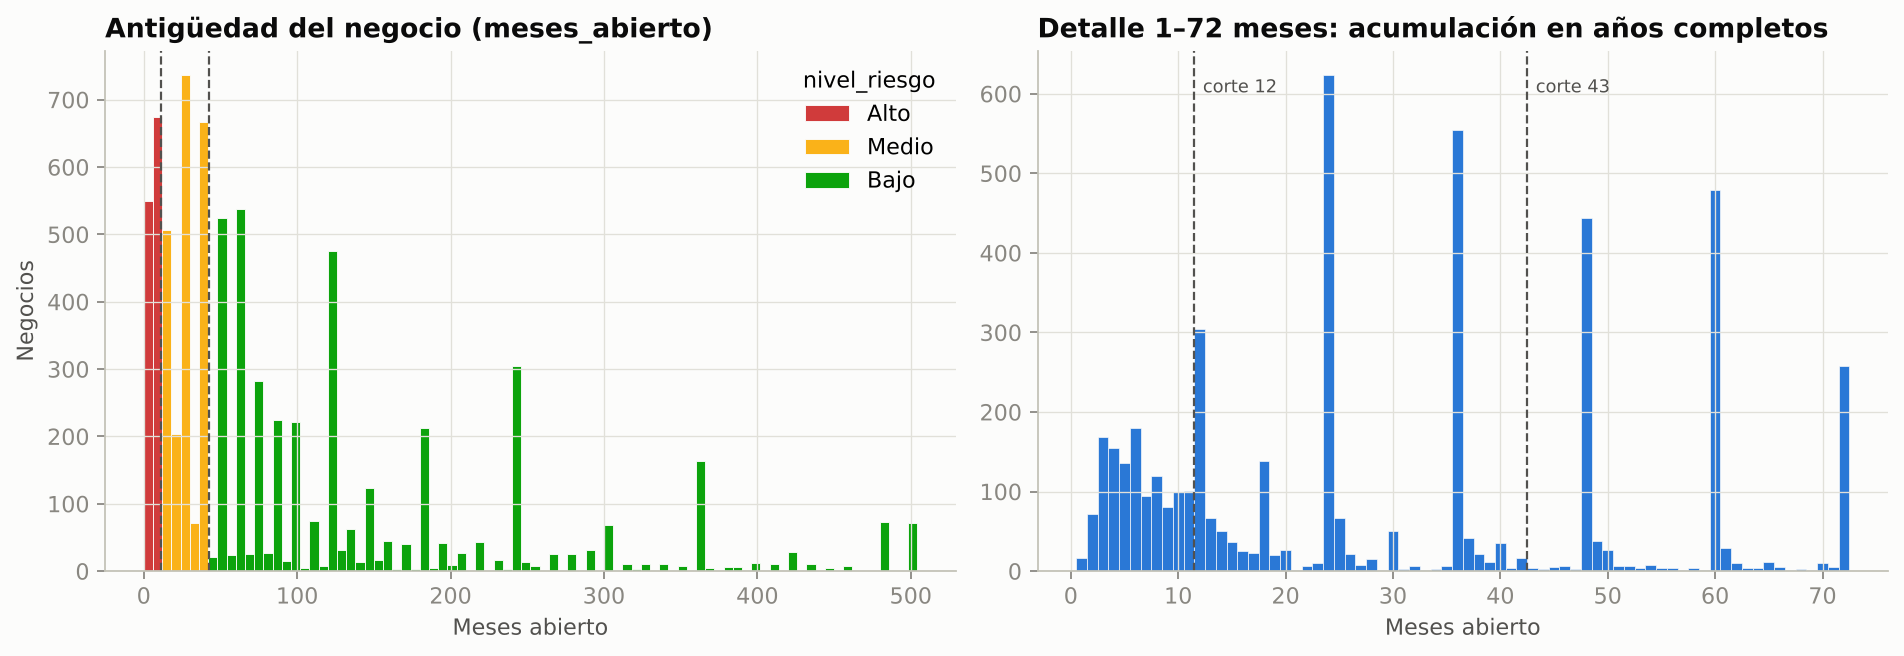

In [4]:
if not (F / "01_distribucion_meses_abierto.png").exists():
    from src import eda; eda.main()
display(pd.read_csv(T / "resumen_numericas.csv", index_col=0).round(1))
display(Image(F / "01_distribucion_meses_abierto.png"))

## 3. Preparación de los datos
### 3.1 Construcción de `nivel_riesgo` (decisión metodológica del proyecto, no clasificación oficial del DANE)

| Clase | Regla exacta | Justificación |
|---|---|---|
| **Alto** | 1 ≤ meses ≤ 11 | Primer año de operación: la etapa con mayor caída de supervivencia reportada para empresas colombianas (Confecámaras). |
| **Medio** | 12 ≤ meses ≤ 42 | Negocio que superó el primer año pero sigue siendo "nuevo": el *Global Entrepreneurship Monitor* (GEM) llama *new business* a los que tienen hasta 42 meses. |
| **Bajo** | meses ≥ 43 | Negocio "establecido" según GEM (más de 42 meses). |

* El ejemplo ilustrativo (12/36) se evaluó y **no** se adoptó: el corte en 36 coincide con un pico de redondeo (555 negocios dicen "3 años" = 36), lo que vuelve frágil la frontera; el umbral GEM de 42 meses tiene respaldo externo y cae en una zona con pocos casos (37–47 meses).
* Los umbrales **no** se eligieron por métricas: se fijaron antes de entrenar.
* Registros con `meses_abierto` nulo, ≤ 0 o no numérico quedarían sin etiqueta y se excluirían (en esta base: 0 casos).

,regla,registros,porcentaje,min,max,median
Alto,1 <= meses_abierto <= 11,1224,16.27,1.0,11.0,6.0
Medio,12 <= meses_abierto <= 42,2200,29.24,12.0,42.0,24.0
Bajo,meses_abierto >= 43,4099,54.49,43.0,500.0,120.0


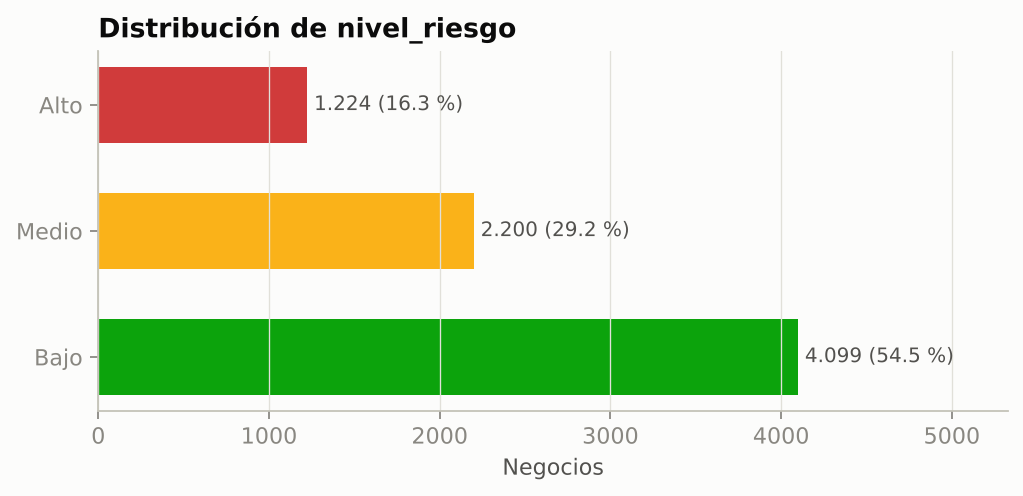

In [5]:
df = prepare_dataset()          # limpieza + etiqueta + verificación de no solapamiento
display(target_distribution(df))
display(Image(F / "02_distribucion_nivel_riesgo.png"))

Desbalance moderado (16 % / 29 % / 54 %). Estrategia: división estratificada, `class_weight="balanced"` (o pesos de muestra en XGBoost) dentro de cada pliegue, y **F1 macro** como métrica principal. No se usa SMOTE ni sobremuestreo.
### 3.2 Auditoría de fuga de información

In [6]:
display(leakage_audit_table())

,variable,tipo,descripcion,uso_previsto,decision,justificacion
0,id_negocio,entero,Número de fila (no es dato del DANE),Ninguno,Excluida de X,Identificador de fila; no aporta información del negocio.
1,meses_abierto,entero,Edad del negocio en meses (P3034),Construcción de la etiqueta,Excluida de X,Se usa exclusivamente para construir la etiqueta nivel_riesgo.
2,nivel_riesgo,categórica,Alto / Medio / Bajo construida desde meses_abierto,Variable objetivo (y),Excluida de X,Es la variable objetivo.
3,donde_funciona,categórica,Dónde funciona principalmente el negocio (P3053),Predictora (X),Incluida,"Característica observable del negocio, conocida al predecir; no deriva de la etiqueta."
4,como_lleva_cuentas,categórica,Principal forma de llevar las cuentas (P640),Predictora (X),Incluida,"Característica observable del negocio, conocida al predecir; no deriva de la etiqueta."
5,tiene_ayudantes,binaria,Si alguien le ayuda en el negocio (P3031),Predictora (X),Incluida,"Característica observable del negocio, conocida al predecir; no deriva de la etiqueta."
6,acepta_transferencias,binaria,Acepta transferencias o pagos por internet (P1764_3),Predictora (X),Incluida,"Característica observable del negocio, conocida al predecir; no deriva de la etiqueta."
7,tiene_nombre_comercial,binaria,Tiene nombre comercial (P3035),Predictora (X),Incluida,"Característica observable del negocio, conocida al predecir; no deriva de la etiqueta."
8,registrado_camara_comercio,binaria,Registro en Cámara de Comercio (P1055),Predictora (X),Incluida,"Característica observable del negocio, conocida al predecir; no deriva de la etiqueta."
9,tiene_RUT,binaria,Tiene RUT ante la DIAN (P1633),Predictora (X),Incluida,"Característica observable del negocio, conocida al predecir; no deriva de la etiqueta."


**Decisiones sobre las variables especiales**
* `meses_abierto`: solo construye la etiqueta → **excluida**.
* `riesgo_financiero`: transformación determinística del ingreso (umbral $650.000), creada por el equipo para otro objetivo → **excluida** por redundante (no aporta información que no esté en el ingreso y añade un umbral arbitrario).
* `le_deja_al_mes_COP`: lo reporta el dueño en la encuesta (disponible al predecir), no se calcula a partir de la antigüedad y su relación con ella es débil (Spearman 0,18) → **incluida**. Su exclusión en el diccionario era por el objetivo anterior.
* `edad_propietario`: disponible al predecir y no derivada de la etiqueta; correlación moderada con la antigüedad (r = 0,42, lógica: un negocio de 20 años suele tener un dueño mayor) → **incluida**, con análisis de sensibilidad y una nota ética (no debe usarse para discriminar por edad).
* `id_negocio`: identificador → **excluida**.

In [7]:
X, y = get_X_y(df)
X_train, X_test, y_train, y_test = split_data(X, y)
assert "meses_abierto" not in X.columns and "nivel_riesgo" not in X.columns
print("Predictoras (", X.shape[1], "):", list(X.columns))
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
pd.DataFrame({"train %": y_train.value_counts(normalize=True).sort_index().values*100,
              "test %": y_test.value_counts(normalize=True).sort_index().values*100}, index=config.CLASS_ORDER).round(2)

Predictoras ( 13 ): ['donde_funciona', 'como_lleva_cuentas', 'visible_desde_la_calle', 'zona', 'tiene_ayudantes', 'acepta_transferencias', 'tiene_nombre_comercial', 'registrado_camara_comercio', 'tiene_RUT', 'usa_internet', 'tiene_redes_sociales', 'edad_propietario', 'le_deja_al_mes_COP']
Entrenamiento: (6018, 13) | Prueba: (1505, 13)


,train %,test %
Alto,16.27,16.28
Medio,29.25,29.24
Bajo,54.49,54.49


### 3.3 Relación descriptiva de las variables con la etiqueta (EDA)

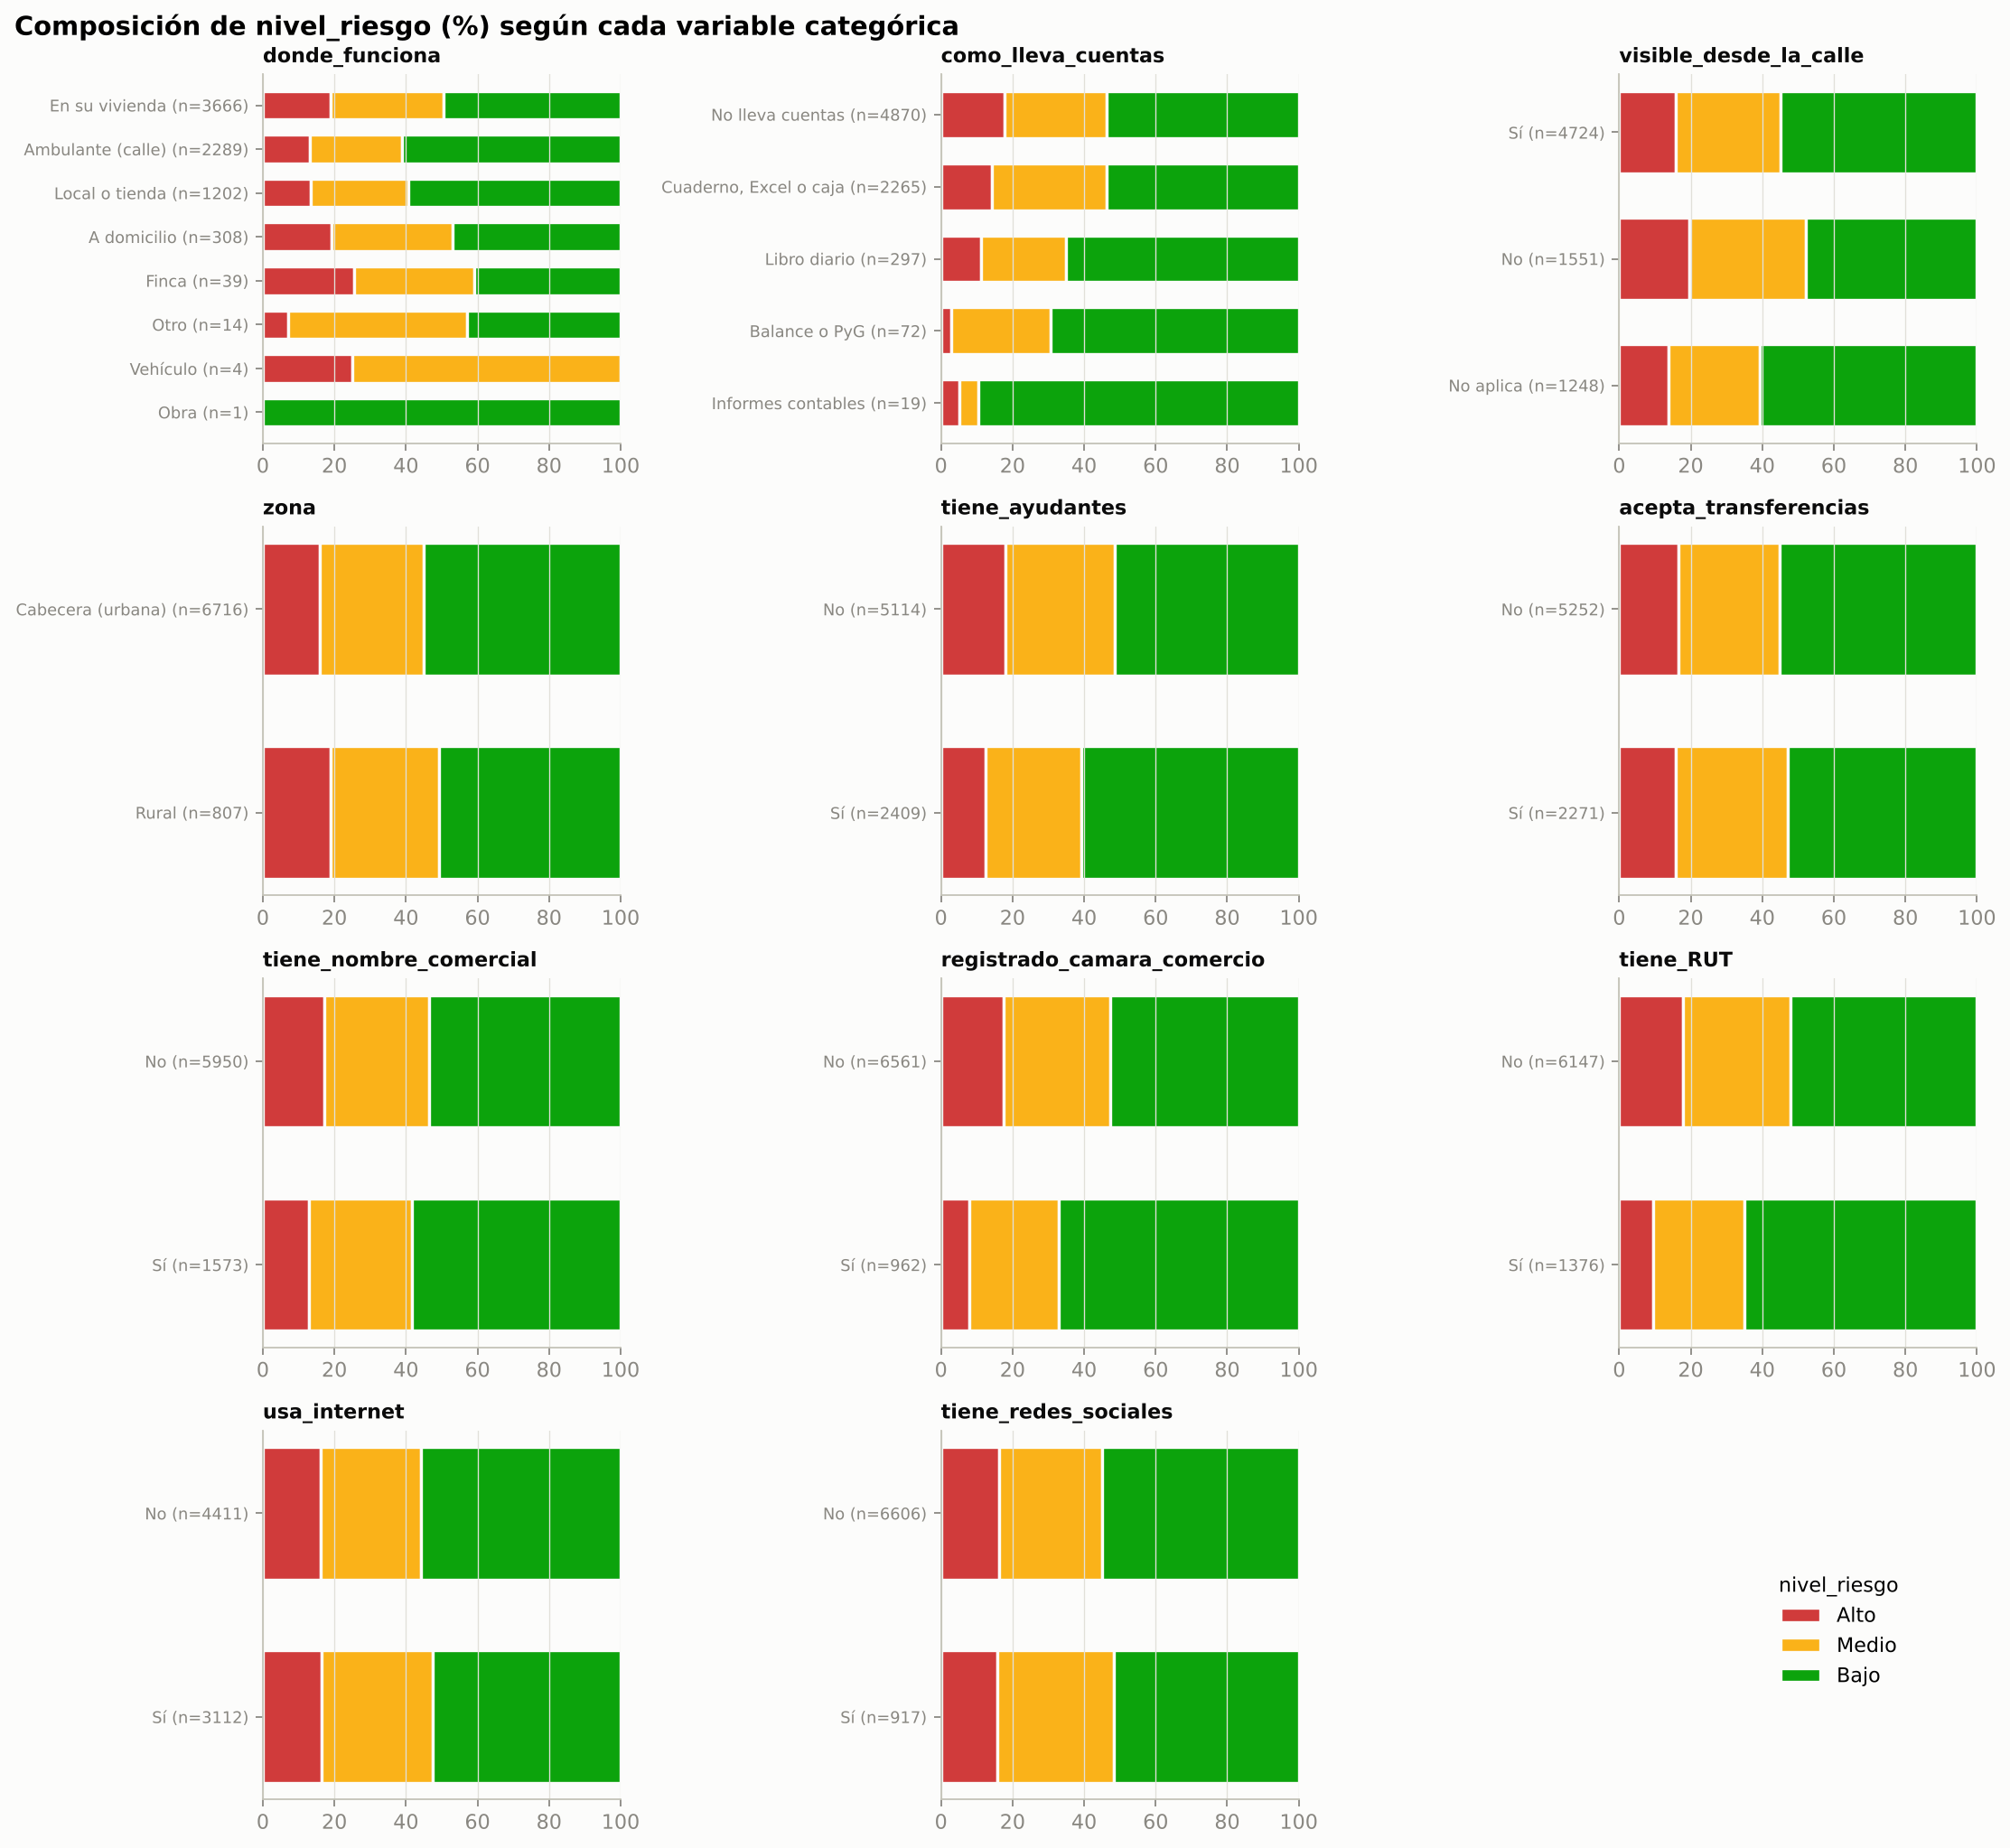

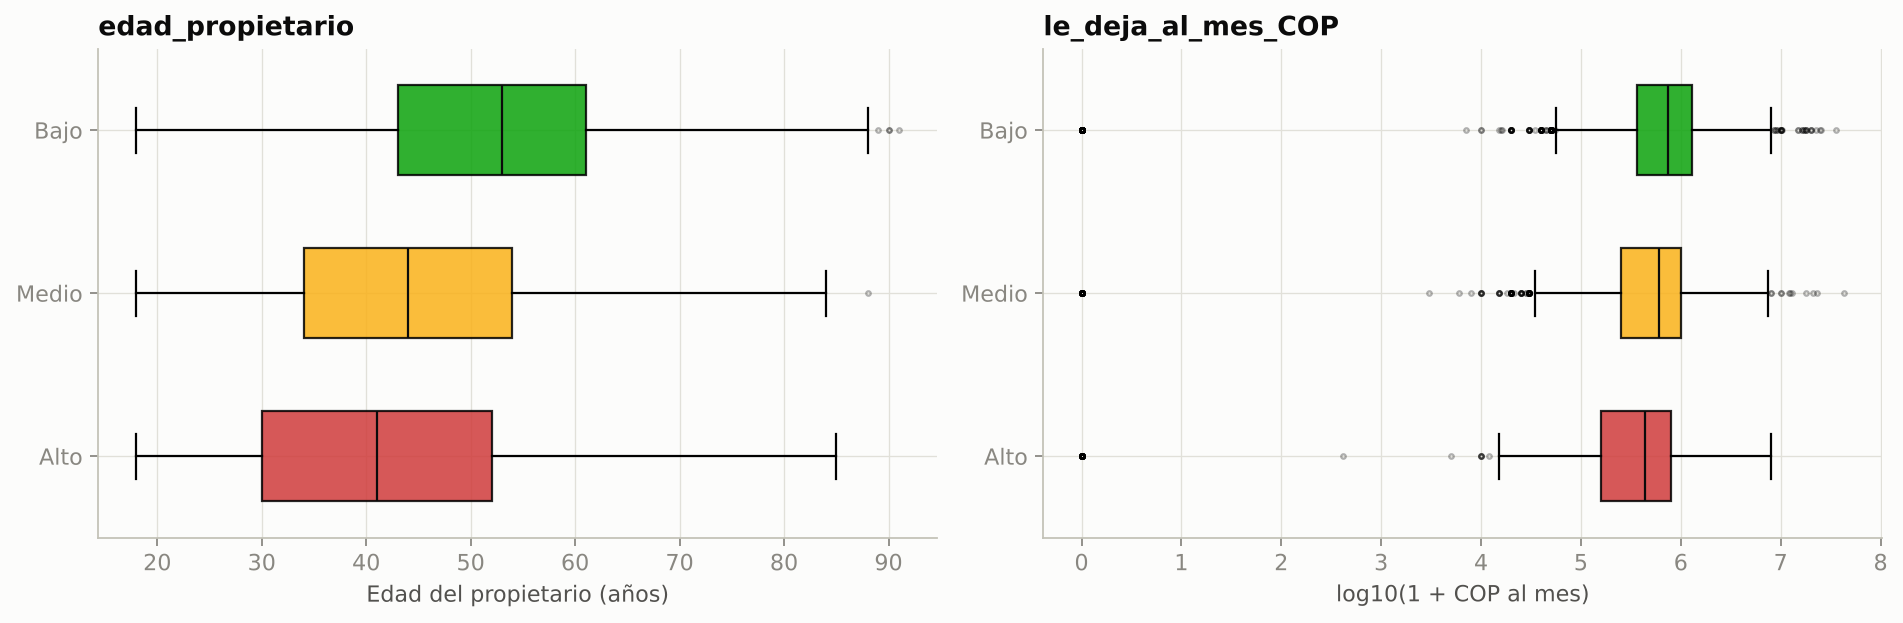

In [8]:
display(Image(F / '03_categoricas_vs_nivel_riesgo.png')); display(Image(F / '04_numericas_vs_nivel_riesgo.png'))

Las variables categóricas muestran diferencias pequeñas entre clases; la edad del propietario y el ingreso son las que más separan los grupos. Esto anticipa un desempeño **modesto**.

## 4. Modelado
* Preprocesamiento en `Pipeline` + `ColumnTransformer` (ajustado solo con train de cada pliegue): moda + One-Hot (infrecuentes agrupadas, desconocidas toleradas) para categóricas; mediana para numéricas; `log1p` para el ingreso; `StandardScaler` **solo** en regresión logística.
* Validación cruzada estratificada de **5 pliegues** (semilla 42) sobre el 80 % de entrenamiento; métrica de búsqueda: **F1 macro**.
* Búsqueda: rejilla completa (logística: 9 valores de C; árbol: 70 combinaciones) y búsqueda aleatoria de 40 combinaciones (Random Forest, XGBoost).
* **Criterio de selección (regla de un error estándar; Hastie, Tibshirani y Friedman, 2009, sec. 7.10):** se calcula el error estándar del mejor F1 macro medio (desviación estándar muestral de los 5 pliegues dividida por √5); entre los modelos con F1 macro medio mayor o igual que *mejor − 1 error estándar*, se elige el más simple e interpretable. El test no participa.

In [9]:
if RETRAIN:
    from src import train; train.main()
cv = pd.read_csv(T / "comparacion_cv.csv")
cv[["nombre", "combinaciones_evaluadas", "cv_f1_macro_media", "cv_f1_macro_desv", "cv_balanced_accuracy_media",
    "cv_accuracy_media", "train_f1_macro_media", "mejores_hiperparametros"]].round(4)

,nombre,combinaciones_evaluadas,cv_f1_macro_media,cv_f1_macro_desv,cv_balanced_accuracy_media,cv_accuracy_media,train_f1_macro_media,mejores_hiperparametros
0,Regresión logística,9,0.4269,0.0111,0.4604,0.4929,0.4406,{'C': 10.0}
1,Árbol de decisión,70,0.4479,0.0108,0.4652,0.4940,0.4636,"{'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 50}"
2,Random Forest,40,0.4460,0.0070,0.4697,0.5131,0.5120,"{'n_estimators': 600, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 6}"
3,XGBoost,40,0.4503,0.0133,0.4739,0.5155,0.4870,"{'colsample_bytree': 0.6705331755251293, 'learning_rate': 0.014048580838867042, 'max_depth': 3, 'min_child_weight': ..."


In [10]:
sel = json.load(open(T / "seleccion_modelo.json", encoding="utf-8"))
print("Modelo final:", sel["modelo_final"]); print(sel["criterio"])
best = cv["cv_f1_macro_media"].max(); ee = cv.loc[cv["cv_f1_macro_media"].idxmax(), "cv_f1_macro_ee"]
print(f"Error estándar del mejor modelo: {ee:.4f}")
print(f"Umbral de equivalencia: {best:.4f} - {ee:.4f} = {best - ee:.4f}")

Modelo final: decision_tree
Regla de un error estándar (Hastie, Tibshirani y Friedman, 2009, sec. 7.10).

Se aplica solo con resultados de validación cruzada:
1. Se toma el modelo con mejor F1 macro medio de CV.
2. Se calcula el error estándar de esa media: desviación estándar muestral
   del F1 macro en los k pliegues dividida por raíz de k.
3. Se consideran equivalentes los modelos cuyo F1 macro medio es mayor o
   igual que (mejor media - un error estándar).
4. Entre los equivalentes se elige el más simple e interpretable
   (regresión logística < árbol < random forest < XGBoost).
Error estándar del mejor modelo: 0.0067
Umbral de equivalencia: 0.4503 - 0.0067 = 0.4436


XGBoost obtuvo el mejor F1 macro de CV (0,4503), con un error estándar de 0,0067. El árbol (0,4479) y Random Forest (0,4460) superan el umbral de equivalencia (0,4436): su diferencia con XGBoost es menor que un error estándar. La regresión logística (0,4269) queda por debajo del umbral. Según la regla, se elige el **árbol de decisión** (profundidad 4, hojas ≥ 50): casi el mismo desempeño, se puede dibujar completo y explicar regla por regla en la aplicación.

**Sensibilidad (solo CV en entrenamiento):**

In [11]:
pd.read_csv(T / 'sensibilidad_variables.csv').round(4)

,escenario,n_variables,cv_f1_macro,cv_f1_macro_desv,cv_balanced_accuracy
0,Todas las variables aprobadas,13,0.4479,0.0108,0.4652
1,Sin le_deja_al_mes_COP,12,0.3998,0.0219,0.4391
2,Sin edad_propietario,12,0.3533,0.0284,0.3910
3,Sin ingreso ni edad,11,0.3705,0.0206,0.4063


Sin la edad del propietario el F1 macro cae de 0,448 a 0,353; sin el ingreso, a 0,400. El modelo depende sobre todo de estas dos variables.
(Que "sin ingreso ni edad" dé 0,371, algo más que "sin edad", se explica porque los hiperparámetros se fijaron para el conjunto completo y por la variación entre pliegues.)

## 5. Evaluación en el conjunto de prueba (usado una sola vez)

In [12]:
if RETRAIN:
    from src import evaluate; evaluate.main()
m = pd.read_csv(T / "metricas_prueba.csv", index_col=0)
m.round(4)

,nombre,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,log_loss,brier_medio
modelo,,,,,,,,,
logistic_regression,Regresión logística,0.4983,0.4744,0.4444,0.4744,0.4375,0.5012,0.9976,0.1978
decision_tree,Árbol de decisión,0.4997,0.4642,0.4488,0.4642,0.4512,0.5104,1.0050,0.1999
random_forest,Random Forest,0.5269,0.4925,0.4695,0.4925,0.4672,0.5318,0.9815,0.1954
xgboost,XGBoost,0.5209,0.4971,0.4697,0.4971,0.4667,0.5265,0.9807,0.1952
baseline_estratificado,Línea base: azar estratificado,0.4113,0.3308,0.3308,0.3308,0.3308,0.4117,21.2191,0.3925
baseline_clase_mayoritaria,Línea base: siempre «Bajo»,0.5449,0.3333,0.1816,0.3333,0.2351,0.3843,16.4053,0.3034


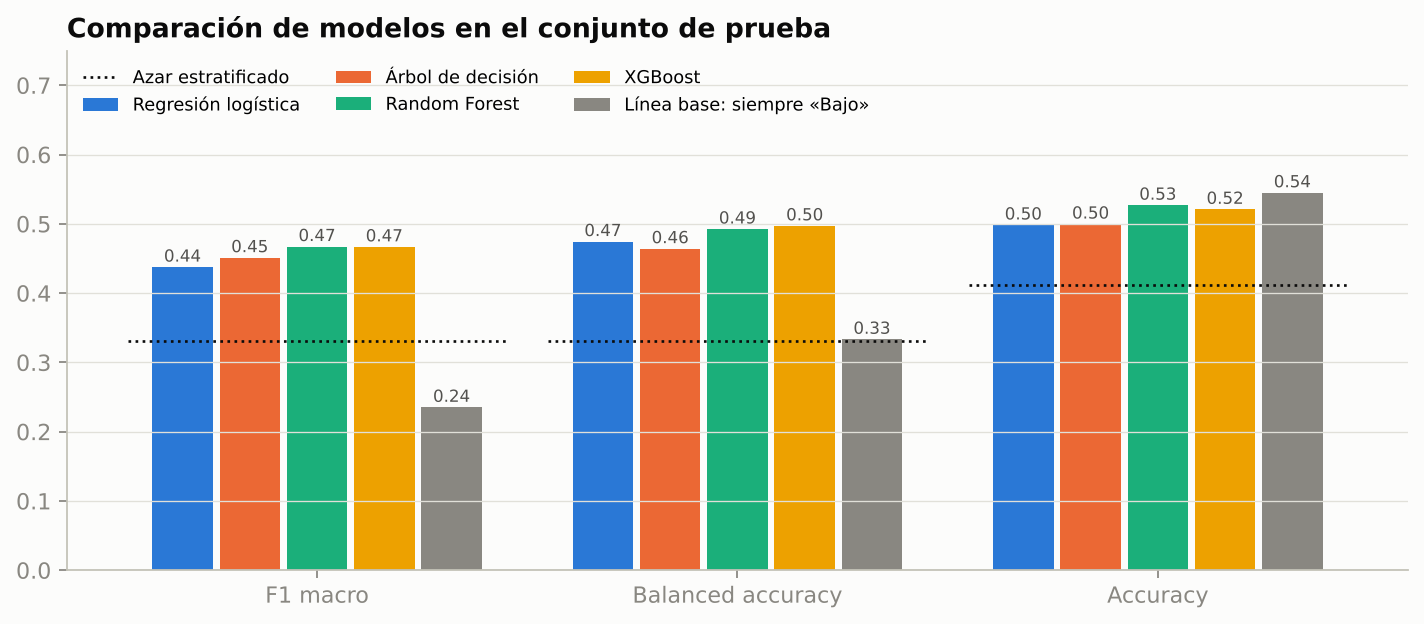

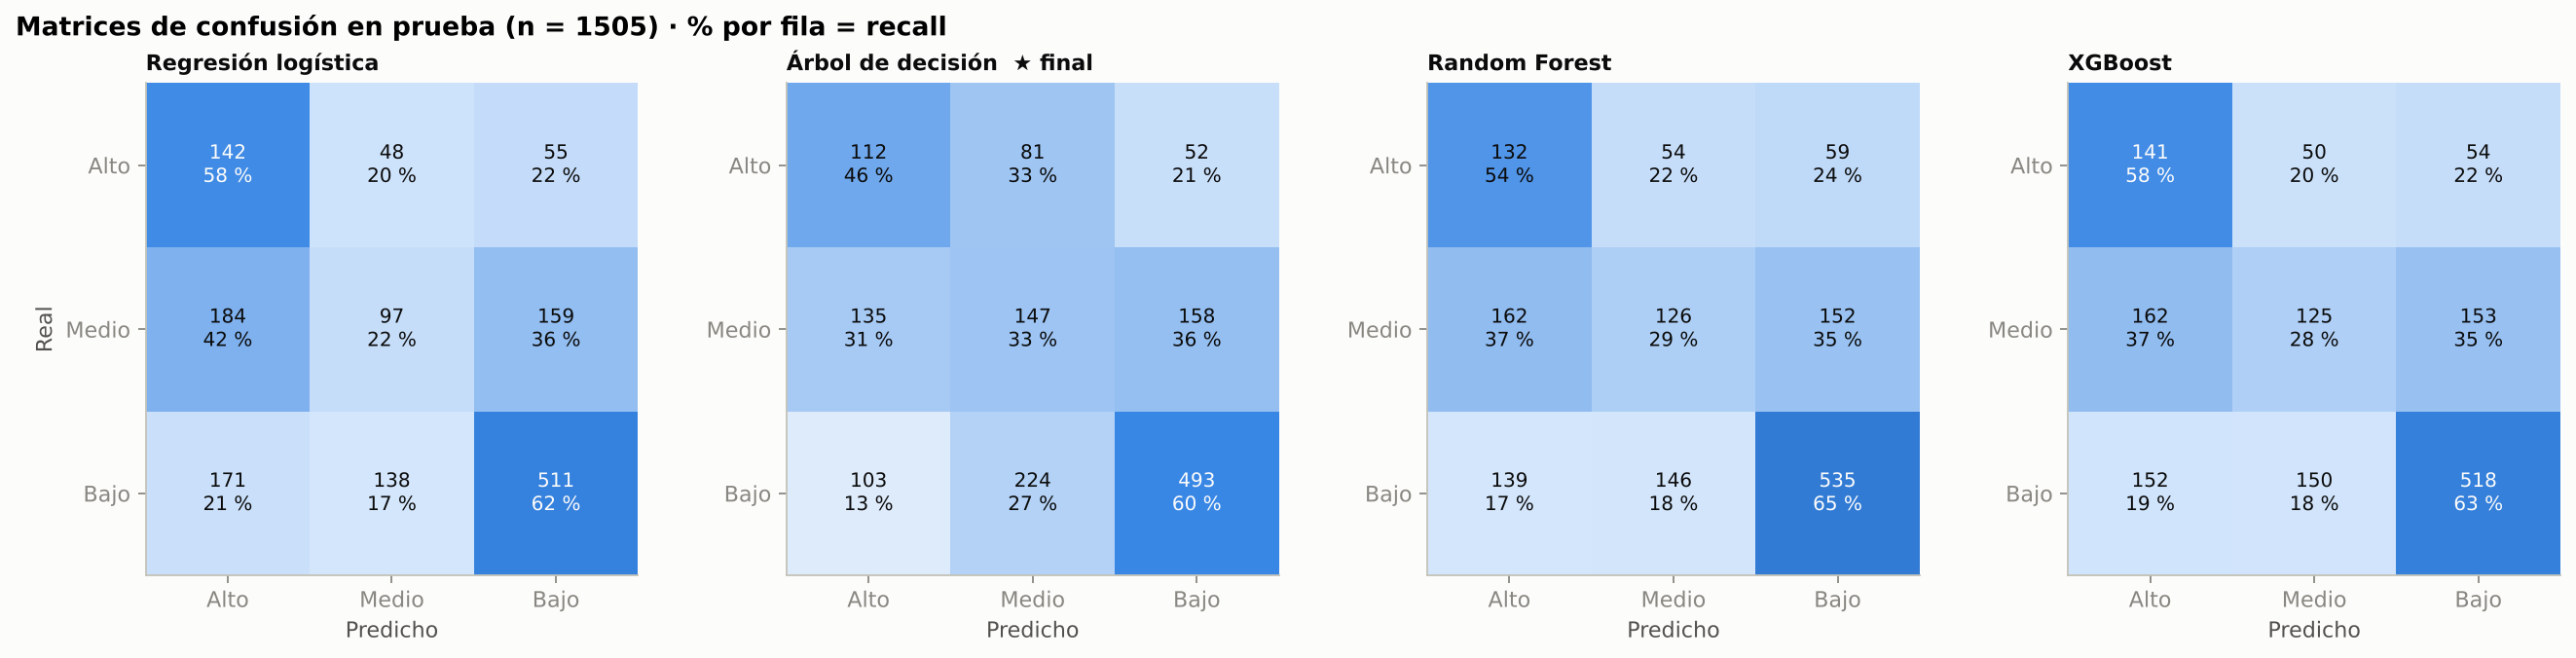

In [13]:
display(Image(F / '06_comparacion_modelos.png')); display(Image(F / '05_matrices_confusion.png'))

clase,Alto,Medio,Bajo
modelo,,,
decision_tree,0.376,0.330,0.647
logistic_regression,0.383,0.268,0.661
random_forest,0.389,0.329,0.683
xgboost,0.403,0.327,0.671


=== Regresión logística ===
              precision    recall  f1-score   support

        Alto      0.286     0.580     0.383       245
       Medio      0.343     0.220     0.268       440
        Bajo      0.705     0.623     0.661       820

    accuracy                          0.498      1505
   macro avg      0.444     0.474     0.438      1505
weighted avg      0.531     0.498     0.501      1505

Matriz de confusión (filas=real, columnas=predicho; orden ['Alto', 'Medio', 'Bajo']):
[[142  48  55]
 [184  97 159]
 [171 138 511]]

=== Árbol de decisión ===
              precision    recall  f1-score   support

        Alto      0.320     0.457     0.376       245
       Medio      0.325     0.334     0.330       440
        Bajo      0.701     0.601     0.647       820

    accuracy                          0.500      1505
   macro avg      0.449     0.464     0.451      1505
weighted avg      0.529     0.500     0.510      1505

Matriz de confusión (filas=real, columnas=predicho;

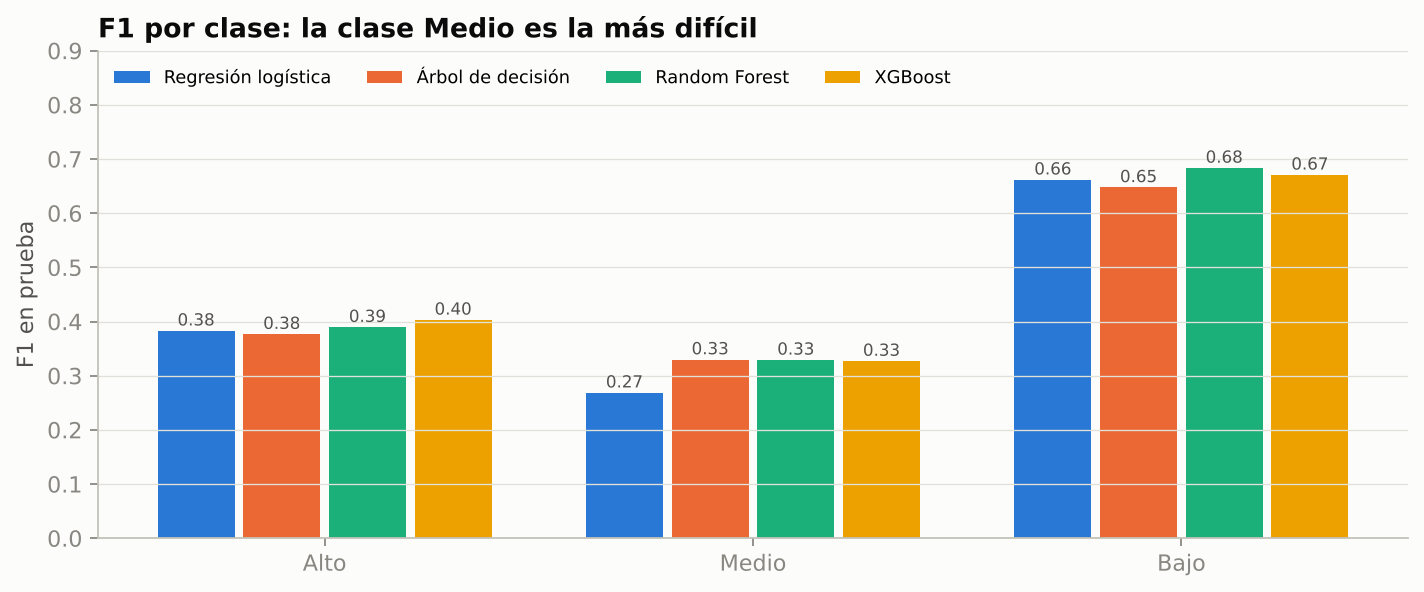

In [14]:
pc = pd.read_csv(T / "metricas_por_clase_prueba.csv")
display(pc.pivot(index="modelo", columns="clase", values="f1")[config.CLASS_ORDER].round(3))
print(open(T / "classification_reports.txt", encoding="utf-8").read().split("=== Random")[0])
display(Image(F / '07_f1_por_clase.png'))

**Lectura de los resultados**
* Los cuatro modelos superan claramente al azar estratificado (F1 macro 0,33) y a "predecir siempre Bajo" (0,24), pero el desempeño es **modesto** (F1 macro 0,44–0,47).
* *Accuracy* engaña: "siempre Bajo" tiene la mayor accuracy (0,54) y es inútil para las clases Alto y Medio. Por eso la selección usa F1 macro.
* En el test, Random Forest y XGBoost superan al árbol en ~0,016 de F1 macro. Esa diferencia es similar a la variación entre pliegues y **no** se usa para cambiar la decisión (hacerlo sería ajustar con el test). Se reporta como hallazgo.
* **Medio** es la clase más difícil (F1 ≈ 0,33): está "entre" las otras dos y sus límites dependen de respuestas redondeadas.

### 5.1 Errores más relevantes

In [15]:
pd.read_csv(T / 'errores_por_tramo_meses.csv').round(3)

,tramo_meses,registros,tasa_error,clase_real
0,1-6,139,0.568,Alto
1,7-11,106,0.509,Alto
2,12-24,278,0.655,Medio
3,25-42,162,0.685,Medio
4,43-60,208,0.553,Bajo
5,61-120,299,0.452,Bajo
6,>120,313,0.246,Bajo


Los errores se concentran en **12–42 meses** (65–69 % de error) y cerca de los cortes; los negocios con más de 10 años se reconocen mejor (25 % de error). Un negocio de 13 meses y uno de 11 son muy parecidos en sus características, pero quedan en clases distintas: es una limitación inherente a convertir una variable continua en categorías.

## 6. Interpretabilidad del modelo final

,variable,importancia_media,importancia_desv
0,edad_propietario,0.0895,0.0089
1,le_deja_al_mes_COP,0.0124,0.0085
2,tiene_ayudantes,0.0020,0.0033
3,visible_desde_la_calle,0.0005,0.0039
4,donde_funciona,0.0004,0.0029
5,zona,0.0000,0.0000
6,como_lleva_cuentas,0.0000,0.0000
7,acepta_transferencias,0.0000,0.0000
8,tiene_nombre_comercial,0.0000,0.0000
9,tiene_RUT,0.0000,0.0000


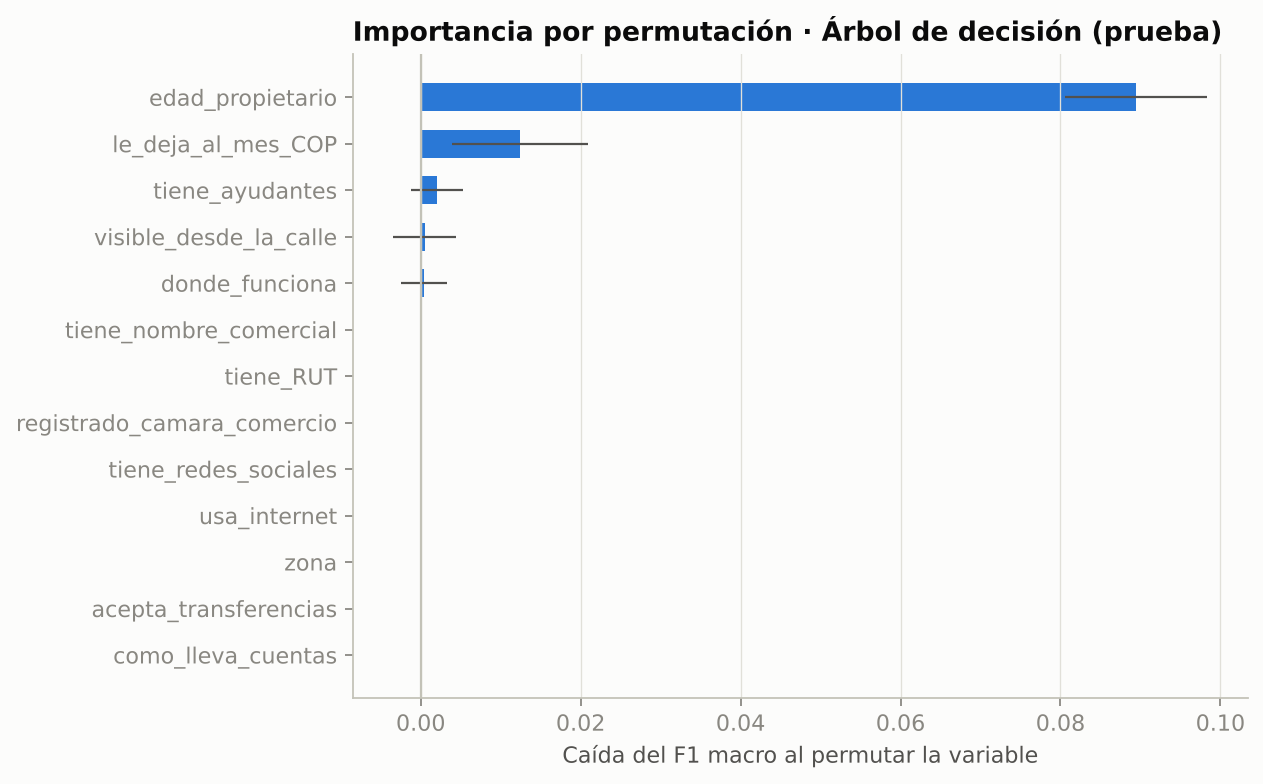

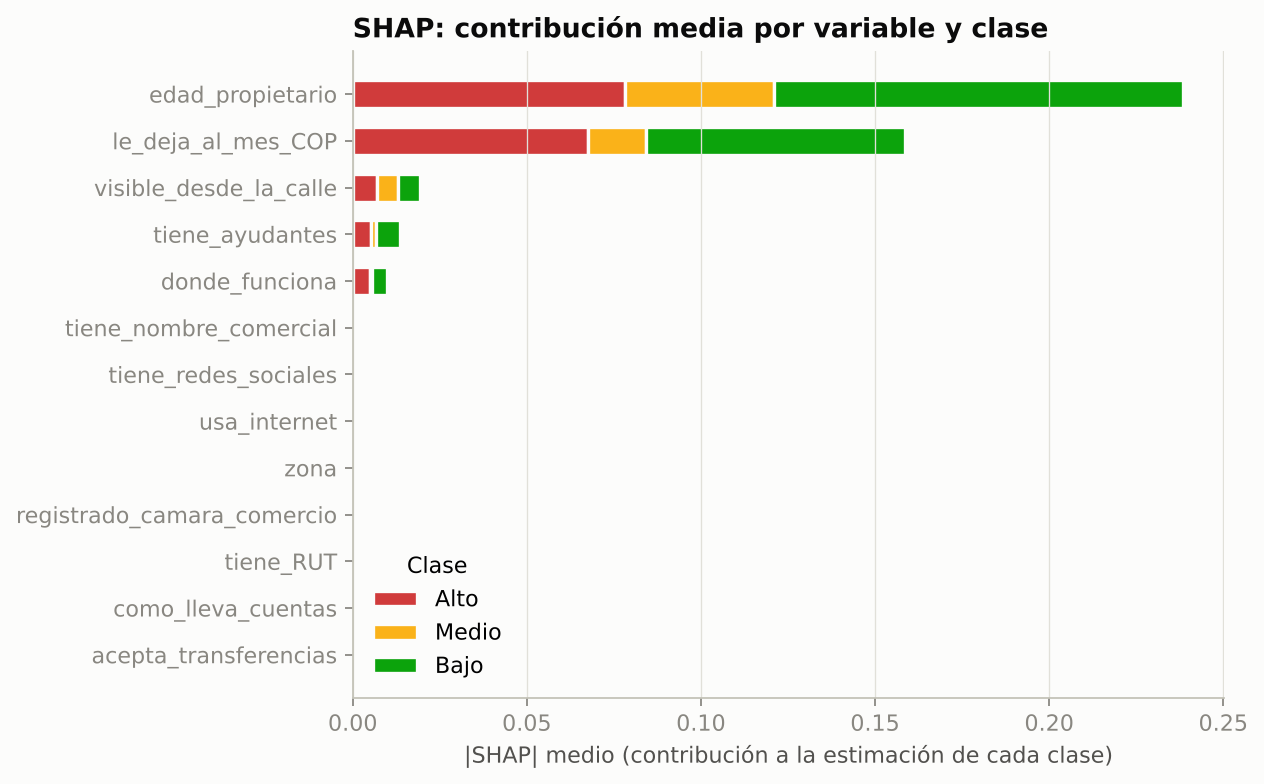

In [16]:
display(pd.read_csv(T / "importancia_permutacion_final.csv").round(4))
display(Image(F / "08_importancia_permutacion.png")); display(Image(F / "10_shap_modelo_final.png"))

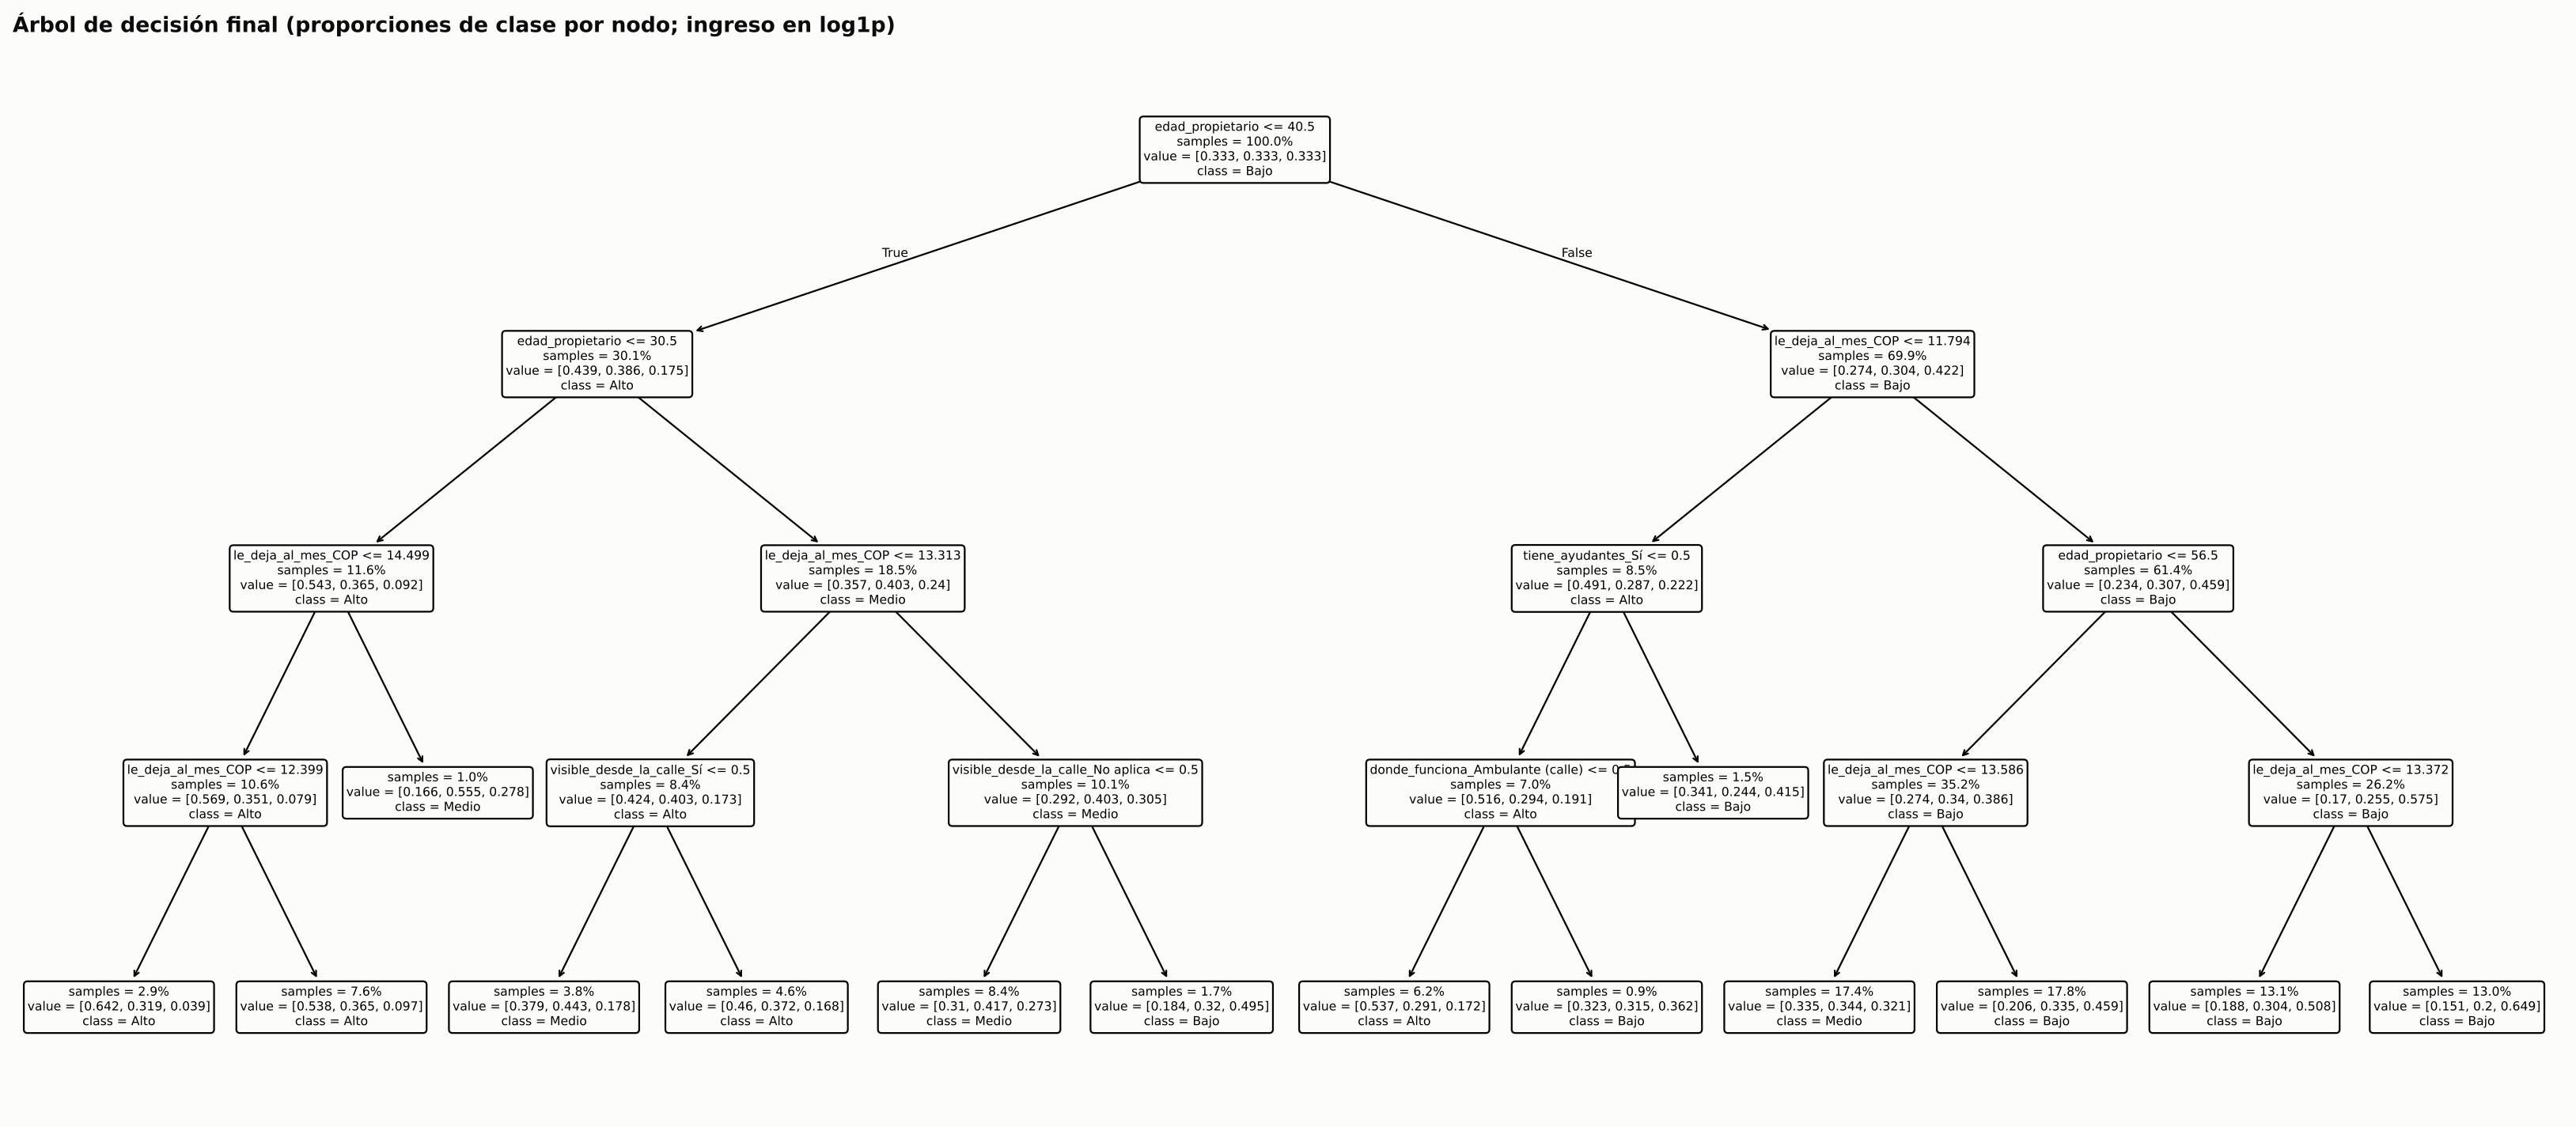

# Reglas del árbol final. le_deja_al_mes_COP está en escala log1p:
# pesos = exp(umbral) - 1 (p. ej. 13,31 -> $603.000 aprox.).

|--- edad_propietario <= 40.50
|   |--- edad_propietario <= 30.50
|   |   |--- le_deja_al_mes_COP <= 14.50
|   |   |   |--- le_deja_al_mes_COP <= 12.40
|   |   |   |   |--- class: Alto
|   |   |   |--- le_deja_al_mes_COP >  12.40
|   |   |   |   |--- class: Alto
|   |   |--- le_deja_al_mes_COP >  14.50
|   |   |   |--- class: Medio
|   |--- edad_propietario >  30.50
|   |   |--- le_deja_al_mes_COP <= 13.31
|   |   |   |--- visible_desde_la_calle_Sí <= 0.50
|   |   |   |   |--- class: Medio
|   |   |   |--- visible_desde_la_calle_Sí >  0.50
|   |   |   |   |--- class: Alto
|   |   |--- le_deja_al_mes_COP >  13.31
|   |   |   |--- visible_desde_la_calle_No aplica <= 0.50
|   |   |   |   |--- class: Medio
|   |   |   |--- visible_desde_la_calle_No aplica >  0.50
|   |   |   |   |--- class: Bajo
|--- edad_propietario >  40.50
|   |--- le_deja_al_mes_COP <= 11.79


In [17]:
display(Image(F / '09_arbol_decision.png')); print(open(T / 'reglas_arbol.txt', encoding='utf-8').read())

* La **edad del propietario** domina (importancia por permutación 0,090; 60 % de la importancia del árbol), seguida del **ingreso mensual** (35 %). Contribuyen marginalmente `tiene_ayudantes`, `visible_desde_la_calle` y `donde_funciona`.
* **Importancia ≠ causalidad.** Que la edad del dueño ayude a clasificar no significa que la edad cause el riesgo: un dueño mayor suele tener un negocio más antiguo simplemente porque ha tenido más tiempo para abrirlo y mantenerlo.
* Coeficientes de la regresión logística (comparación): `reports/tables/coeficientes_regresion_logistica.csv`.
* Las "probabilidades" del árbol son proporciones de clase (ponderadas) en la hoja: indican qué tan mezclado está el grupo, no la probabilidad de cerrar. Log-loss en test 1,005 y Brier medio 0,200 (frente a 0,39 del azar).

## 7. Despliegue
El pipeline completo se guarda en `models/modelo_final.joblib` y lo usa la API FastAPI (`app/main.py`). Ver `README.md`.

In [18]:
from src.predict import predict
caso = {"donde_funciona": "Ambulante (calle)", "como_lleva_cuentas": "No lleva cuentas", "visible_desde_la_calle": "No aplica",
        "zona": "Cabecera (urbana)", "tiene_ayudantes": "No", "acepta_transferencias": "Sí", "tiene_nombre_comercial": "No",
        "registrado_camara_comercio": "No", "tiene_RUT": "No", "usa_internet": "Sí", "tiene_redes_sociales": "No",
        "edad_propietario": 23, "le_deja_al_mes_COP": 410000}
r = predict(caso); {k: r[k] for k in ("nivel_riesgo", "puntajes_por_clase", "reglas_aplicadas")}

{'nivel_riesgo': 'Alto',
 'puntajes_por_clase': {'Alto': 0.538, 'Medio': 0.3654, 'Bajo': 0.0966},
 'reglas_aplicadas': ['Edad del propietario de hasta 40 años',
  'Edad del propietario de hasta 30 años',
  'Le deja al mes hasta $1.981.000',
  'Le deja al mes más de $242.487']}

## 8. Limitaciones y conclusiones
1. **Sesgo de supervivencia:** no hay negocios cerrados; la etiqueta mide antigüedad, no fracaso.
2. **Corte transversal:** una sola medición (2024); no se observa la evolución del negocio.
3. **Señal débil:** las variables disponibles explican poco de la antigüedad (F1 macro ≈ 0,45).
4. **Respuestas redondeadas y autorreportadas** (meses e ingresos).
5. **Umbrales:** decisión del proyecto; otros cortes cambiarían los resultados.
6. **Factores de expansión:** el modelo no usa los pesos muestrales del DANE; las proporciones describen la muestra, no la población.

Para predecir **cierres reales** se necesitaría un panel que siga a los mismos negocios en el tiempo (p. ej., registros de renovación de matrícula mercantil o encuestas repetidas) y variables de resultado observadas después del momento de predicción.